In [62]:
%reload_ext autoreload
%autoreload 2

from turbos.sim.p3d.p3d import P3D
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

run = P3D(
    "/archive/tulasi/MEGARUNS_DATA_SUBSET/149p6",
    filenum="000",
)
# #419
# ds = run.load_xarray(419, variables=['Pe', 'ue', 'Pi', 'ui', 'ne', 'ni', 'E'])
# print(ds)
ds = xr.open_dataset('../data/149p6_rs.nc')

In [63]:
from turbos.filter import kfilter
kf = 150

ds['Pe'] = kfilter(ds['Pe'], kf)
ds['ue'] = kfilter(ds['ue'], kf)
ds['Pi'] = kfilter(ds['Pi'], kf)
ds['ui'] = kfilter(ds['ui'], kf)

In [64]:
print(len(ds.x))

4096


In [65]:
from turbos.pressure_strain import pressure_strain
PSe = pressure_strain(ds['Pe'], ds['ue'])
ds['PiDe'], ds['pthe'] = PSe['PiD'], PSe['pth']

PSi = pressure_strain(ds['Pi'], ds['ui'])
ds['PiDi'], ds['pthi']  = PSi['PiD'], PSi['pth']
ds['JE'] = (ds["J"] * ds["E"]).sum("c")

In [66]:
from scipy.ndimage import uniform_filter, gaussian_filter

def boxcar_filter(field, ell, dx, dy):
    nx = max(1, round(ell / dx))
    ny = max(1, round(ell / dy))

    nx += (nx % 2 == 0)
    ny += (ny % 2 == 0)

    return uniform_filter(
        field,
        size=(len(ds.x.values), len(ds.y.values)),
        mode="wrap"
    )

In [67]:
def coarse_grain(field, ell, dx, dy, kind='boxcar'):
    """Centered 2D filter with periodic boundary conditions.

    For boxcar, ell is the approximate filter width in both x and y.
    For Gaussian, ell is sigma in each spatial direction (one convention).
    """
    if ell == 0:
        return field
    if kind == 'boxcar':
        def odd_width(width):
            n = max(1, int(round(width)))
            return n if n % 2 else n + 1
        widths = (odd_width(ell / dx), odd_width(ell / dy))
        return uniform_filter(field, size=widths, mode='wrap')
    elif kind == 'gaussian':
        return gaussian_filter(field, sigma=(ell / dx, ell / dy),
                               mode='wrap', truncate=4.0)
    else:
        raise ValueError("kind must be 'boxcar' or 'gaussian'")

In [68]:
ns = np.logspace(0, 1, num=10)

In [125]:
# dx = (ds.x[1] - ds.x[0]).values
# dy = (ds.y[1] - ds.y[0]).values


# n = 20
# species = 'i'
# # ns = np.logspace(np.log10(0.05), np.log10(70), num=n)
# # ells = ns * dx
# ells = np.logspace(np.log10(5e-2), np.log10(70), num=n)
# # print(ells)
# i = 0
# l_filter = {'ptheta': [], 'PiD': [], 'total': []}
# for ell in np.asarray(ells):
#     print(i, ell)
#     i = i + 1
#     Pe_bar = xr.apply_ufunc(
#         coarse_grain,
#         ds[f'P{species}'],
#         input_core_dims=[["x", "y"]],
#         output_core_dims=[["x", "y"]],
#         kwargs={"ell": ell, "dx": dx, "dy": dy, "kind": "boxcar"},
#         vectorize=True,
#     )

#     ne_bar = coarse_grain(ds[f'n{species}'], ell, dx, dy, kind="boxcar")

#     ue_tilde = ds[f'u{species}'].copy()

#     for i in range(3):
#         nue_bar = coarse_grain(
#             ds[f'n{species}'] * ds[f'u{species}'].isel(c=i),
#             ell,
#             dx,
#             dy,
#             kind="boxcar"
#         )

#         ue_tilde.loc[{"c": ds[f'u{species}'].c.values[i]}] = nue_bar / ne_bar


#     PS = pressure_strain(Pe_bar, ue_tilde)
#     l_filter['ptheta'].append(np.mean(PS['pth'].values))
#     l_filter['PiD'].append(np.mean(PS['PiD'].values))
#     l_filter['total'].append(np.mean((PS['pth'] + PS['PiD']).values))


In [126]:
# print(l_filter['ptheta'])

np.mean(PS['pth'].values)

np.float64(9.29733469260294e-07)

In [127]:
print(ells)

[5.00000000e-02 7.32075193e-02 1.07186818e-01 1.56937620e-01
 2.29780277e-01 3.36432881e-01 4.92588332e-01 7.21223397e-01
 1.05597951e+00 1.54611281e+00 2.26374167e+00 3.31445824e+00
 4.85286531e+00 7.10532461e+00 1.04032638e+01 1.52319426e+01
 2.23018547e+01 3.26532691e+01 4.78092966e+01 7.00000000e+01]


In [128]:
import json

json_output = json.dumps(l_filter, indent=4, )
print(json_output)

with open("../data/l_filter(i).json", "w") as f:
    f.write(json_output)

{
    "ptheta": [
        1.3724682289619516e-05,
        1.409010685782415e-05,
        1.409010685782415e-05,
        1.388749340145586e-05,
        1.3536821203002792e-05,
        1.3098236684669712e-05,
        1.2108856799039866e-05,
        1.0209016718967394e-05,
        8.662335732500367e-06,
        6.778026459066009e-06,
        5.331044606983956e-06,
        4.359774073875097e-06,
        3.750269027469555e-06,
        3.4444408101162053e-06,
        3.2825241045446757e-06,
        3.288856065229446e-06,
        3.101761559202283e-06,
        2.5600029082574184e-06,
        1.801059258651695e-06,
        8.830977695522925e-07
    ],
    "PiD": [
        7.008391536355045e-05,
        6.998978488183896e-05,
        6.998978488183896e-05,
        6.877254489511346e-05,
        6.693418935618775e-05,
        6.470206996726941e-05,
        5.9676586788940296e-05,
        4.960610510699857e-05,
        4.0626254709693726e-05,
        2.800692322208695e-05,
        1.6110519084625

In [129]:
with open("../data/l_filter(i).json", "r", encoding="utf-8") as file:
    li_filter = json.load(file)

with open("../data/l_filter(e).json", "r", encoding="utf-8") as file:
    l_filter = json.load(file)


total = {'ptheta': [], 'PiD': [], 'total': []}

total['ptheta'] = np.array(li_filter['ptheta']) + np.array(l_filter['ptheta'])
total['PiD'] = np.array(li_filter['PiD']) + np.array(l_filter['PiD'])
total['total'] =  np.array(li_filter['PiD']) + np.array(li_filter['ptheta']) + np.array(l_filter['PiD']) + np.array(l_filter['ptheta'])

In [130]:
print(total['total'])

[1.67617195e-04 1.68159783e-04 1.68159783e-04 1.65320077e-04
 1.60942021e-04 1.55600613e-04 1.43570887e-04 1.19630244e-04
 9.85771809e-05 6.95698994e-05 4.28831274e-05 2.33152090e-05
 1.17921300e-05 6.75421996e-06 4.32405186e-06 5.22628338e-06
 6.71061344e-06 6.99778420e-06 5.87557846e-06 3.71277691e-06]


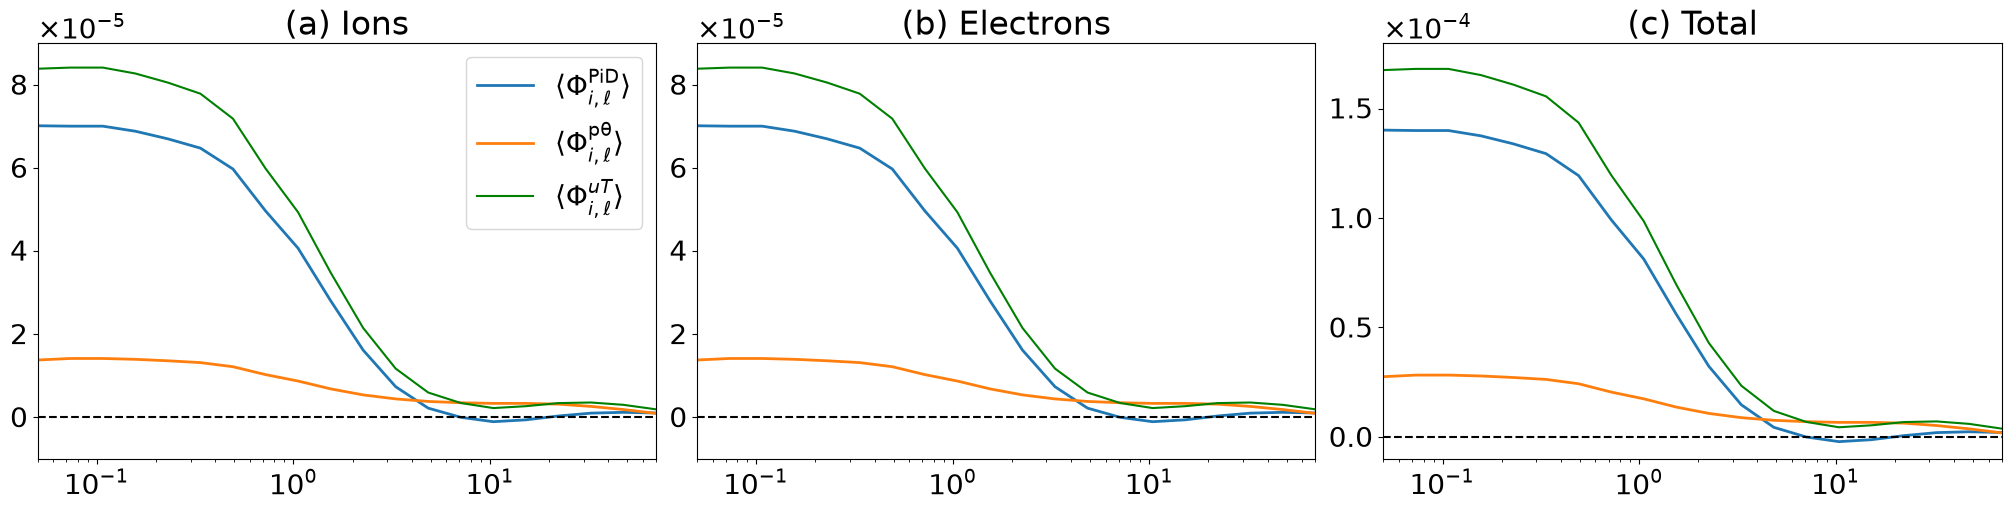

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5), layout = 'constrained')
plt.rcParams.update({'font.size': 20})
for a in ax.ravel():
    a.ticklabel_format(axis="both", style="sci", scilimits=(0, 0), useMathText=True)
n = 20
ells = np.logspace(np.log10(5e-2), np.log10(70), num=n)
ax[0].semilogx(ells, li_filter['PiD'], color='tab:blue', lw=2, label=r'$\langle \Phi_{i,\ell}^{\mathrm{PiD}}\rangle$')
ax[0].semilogx(ells, li_filter['ptheta'], color='tab:orange', lw=2, label = r'$\langle \Phi_{i,\ell}^{\mathrm{p \theta}}\rangle$')
ax[0].semilogx(ells, li_filter['total'], c = 'green', label = r'$\langle \Phi_{i,\ell}^{uT} \rangle$')
ax[0].axhline(0, ls = '--', c = 'black')
ax[0].set_ylim(-1e-5, 9e-5)
ax[0].set_xlim(5e-2, 70)
ax[0].set_title('(a) Ions')


ax[1].semilogx(ells, l_filter['PiD'], color='tab:blue', lw=2, label=r'$\langle \Phi_{e,\ell}^{\mathrm{PiD}}\rangle$')
ax[1].semilogx(ells, l_filter['ptheta'], color='tab:orange', lw=2, label = r'$\langle \Phi_{e,\ell}^{\mathrm{p \theta}}\rangle$')
ax[1].semilogx(ells, l_filter['total'], c = 'green', label = r'$\phi_{e,\ell}^{uT}$')
ax[1].axhline(0, ls = '--', c = 'black')
ax[1].set_ylim(-1e-5, 9e-5)
ax[1].set_xlim(5e-2, 70)
ax[1].set_title('(b) Electrons')

ax[2].semilogx(ells, total['PiD'], color='tab:blue', lw=2, label=r'$\langle \Phi^{\mathrm{PiD}}\rangle$')
ax[2].semilogx(ells, total['ptheta'], color='tab:orange', lw=2, label = r'$\phi_e^{p \theta}$')
ax[2].semilogx(ells, total['total'], c = 'green', label = r'$\phi_{e,\ell}^{uT}$')
ax[2].axhline(0, ls = '--', c = 'black')
ax[2].set_ylim(-1e-5, 18e-5)
ax[2].set_xlim(5e-2, 70)
ax[2].set_title('(c) Total')

ax[0].legend()



fig.savefig('../fig/SF_PS.png', dpi = 300)


